GLM v2    deviance per fold: [0.306  0.3082 0.308  0.3136 0.3058] | mean 0.3083
Boosting  deviance per fold: [0.302  0.3038 0.3026 0.3095 0.3011] | mean 0.3038
GLM v2 minus boosting: [0.004  0.0044 0.0055 0.0042 0.0047] | mean 0.0046 | folds where boosting is better: 5
GLM v2    Gini per fold: [0.323  0.3192 0.3176 0.2964 0.3161] | mean 0.3145
Boosting  Gini per fold: [0.3429 0.3378 0.3474 0.3187 0.3425] | mean 0.3379
Boosting minus GLM v2 (Gini): [0.0199 0.0186 0.0298 0.0223 0.0264] | mean 0.0234 | folds better: 5

=== lift: GLM v2 ===
     exposure  actual  predicted  actual_freq  pred_freq  actual/predicted
g                                                                         
0  28579.3623  1361.0  1368.3598       0.0476     0.0479            0.9946
1  28579.0494  1606.0  1654.8397       0.0562     0.0579            0.9705
2  28579.8947  1722.0  1831.5481       0.0603     0.0641            0.9402
3  28578.7484  1890.0  1982.5949       0.0661     0.0694            0.9533
4  2858

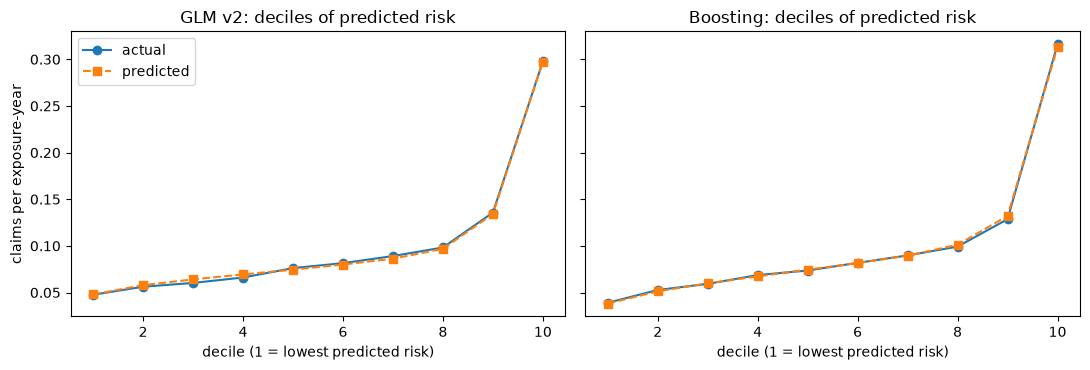


    model  exposure >=  policies  actual/predicted
  GLM v2         0.75    189162             0.823
  GLM v2         0.90    154218             0.818
  GLM v2         0.99    135977             0.824
Boosting         0.75    189162             0.827
Boosting         0.90    154218             0.824
Boosting         0.99    135977             0.831

    model segment (exposure >= 0.9)  policies  actual/predicted
  GLM v2                     age 0      1211             0.396
  GLM v2                    age 1+    153007             0.827
Boosting                     age 0      1211             0.384
Boosting                    age 1+    153007             0.834


In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import load_train, poisson_deviance, N_FOLDS, PROCESSED

train = load_train()
y = train["ClaimNb"].to_numpy(float)
expo = train["Exposure"].to_numpy(float)
masks = [(train["Fold"] == f).to_numpy() for f in range(N_FOLDS)]

preds = {
    "GLM v2":   pd.read_csv(PROCESSED / "oof_glm_x.csv")["pred_claims"].to_numpy(),
    "Boosting": pd.read_csv(PROCESSED / "oof_gbm.csv")["pred_claims"].to_numpy(),
}
for p in preds.values():
    assert len(p) == len(train)

# 1) Deviance per fold, paired
dev = {name: np.array([poisson_deviance(y[m], p[m]) for m in masks]) for name, p in preds.items()}
for name, s in dev.items():
    print(f"{name:9s} deviance per fold:", s.round(4), "| mean", round(s.mean(), 4))
dd = dev["GLM v2"] - dev["Boosting"]
print("GLM v2 minus boosting:", dd.round(4), "| mean", round(dd.mean(), 4), "| folds where boosting is better:", int((dd > 0).sum()))

# 2) Gini: how well do the predictions RANK risk? (exposure-weighted ordered Lorenz curve)
def gini(y, pred_claims, expo):
    freq = pred_claims / expo
    order = np.argsort(freq, kind="mergesort")                       # from lowest to highest predicted frequency
    x = np.r_[0.0, np.cumsum(expo[order]) / expo.sum()]               # cumulative share of exposure
    c = np.r_[0.0, np.cumsum(y[order]) / y.sum()]                     # cumulative share of claims
    return 1 - 2 * np.sum((x[1:] - x[:-1]) * (c[1:] + c[:-1]) / 2)    # 1 - 2 x area under the curve

g = {name: np.array([gini(y[m], p[m], expo[m]) for m in masks]) for name, p in preds.items()}
for name, s in g.items():
    print(f"{name:9s} Gini per fold:", s.round(4), "| mean", round(s.mean(), 4))
d = g["Boosting"] - g["GLM v2"]
print("Boosting minus GLM v2 (Gini):", d.round(4), "| mean", round(d.mean(), 4), "| folds better:", int((d > 0).sum()))

# 3) Lift: policies sorted by predicted risk, cut into 10 groups of EQUAL EXPOSURE
def lift_table(y, pred_claims, expo, n=10):
    freq = pred_claims / expo
    order = np.argsort(freq, kind="mergesort")
    cum = np.cumsum(expo[order]) / expo.sum()
    group = np.minimum((cum * n).astype(int), n - 1)
    t = pd.DataFrame({"g": group, "y": y[order], "pred": pred_claims[order], "expo": expo[order]}).groupby("g").agg(
        exposure=("expo", "sum"), actual=("y", "sum"), predicted=("pred", "sum"))
    t["actual_freq"] = t["actual"] / t["exposure"]
    t["pred_freq"] = t["predicted"] / t["exposure"]
    t["actual/predicted"] = t["actual"] / t["predicted"]
    return t.round(4)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    t = lift_table(y, p, expo)
    print(f"\n=== lift: {name} ===")
    print(t.to_string())
    ax.plot(t.index + 1, t["actual_freq"], "o-", label="actual")
    ax.plot(t.index + 1, t["pred_freq"], "s--", label="predicted")
    ax.set_title(f"{name}: deciles of predicted risk"); ax.set_xlabel("decile (1 = lowest predicted risk)")
axes[0].set_ylabel("claims per exposure-year"); axes[0].legend()
plt.tight_layout(); plt.show()

# 4) Annual-level calibration: actual / predicted claims for LONG policies (the relevant ones for an annual contract)
rows = []
for name, p in preds.items():
    for lo in [0.75, 0.9, 0.99]:
        m = expo >= lo
        rows.append({"model": name, "exposure >=": lo, "policies": int(m.sum()), "actual/predicted": y[m].sum() / p[m].sum()})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

long_ = expo >= 0.9
age0 = (train["VehAge"] == 0).to_numpy()
rows = []
for name, p in preds.items():
    for label, m in [("age 0", long_ & age0), ("age 1+", long_ & ~age0)]:
        rows.append({"model": name, "segment (exposure >= 0.9)": label, "policies": int(m.sum()), "actual/predicted": y[m].sum() / p[m].sum()})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))